In [ ]:
!pip install yfinance torch torchdiffeq scikit-learn

note : memastikan library yang dibutuhkan sudah tersedia. yfinance digunakan untuk mengambil data saham, PyTorch untuk membangun Neural ODE, torchdiffeq untuk penyelesaian persamaan diferensial, dan scikit-learn untuk preprocessing serta evaluasi

IMPORT LIBRATY

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchdiffeq import odeint

import random

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error

plt.style.use("default")

print("Library berhasil diimport.")

Library berhasil diimport.


note : mengimpor seluruh library yang digunakan. NumPy untuk operasi numerik, Pandas untuk pengolahan data, Matplotlib untuk visualisasi, PyTorch untuk neural network, dan odeint dari torchdiffeq untuk menyelesaikan persamaan diferensial.

RANDOM SEED

In [ ]:
def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)

device = torch.device("cpu")

print("Device :", device)
print("Seed   : 42")

Device : cpu
Seed   : 42


note : menetapkan random seed sebesar 42. Tujuannya agar proses yang bersifat acak, terutama inisialisasi parameter model, menghasilkan kondisi yang konsisten ketika program dijalankan kembali. Pada penelitian ini proses dijalankan menggunakan CPU. Angka 42 tidak memiliki makna khusus secara matematis. Saya menggunakan 42 sebagai nilai seed tetap agar eksperimen dapat direproduksi

DOWNLOAD DATA

[*********************100%***********************]  1 of 1 completed

Jumlah data : 279


,Close
Date,
2025-06-02,9100.0
2025-06-03,9050.0
2025-06-04,8975.0
2025-06-05,8925.0
2025-06-10,9100.0


,Close
Date,
2026-07-24,6275.0
2026-07-27,6300.0
2026-07-28,6225.0
2026-07-29,6275.0
2026-07-30,6450.0


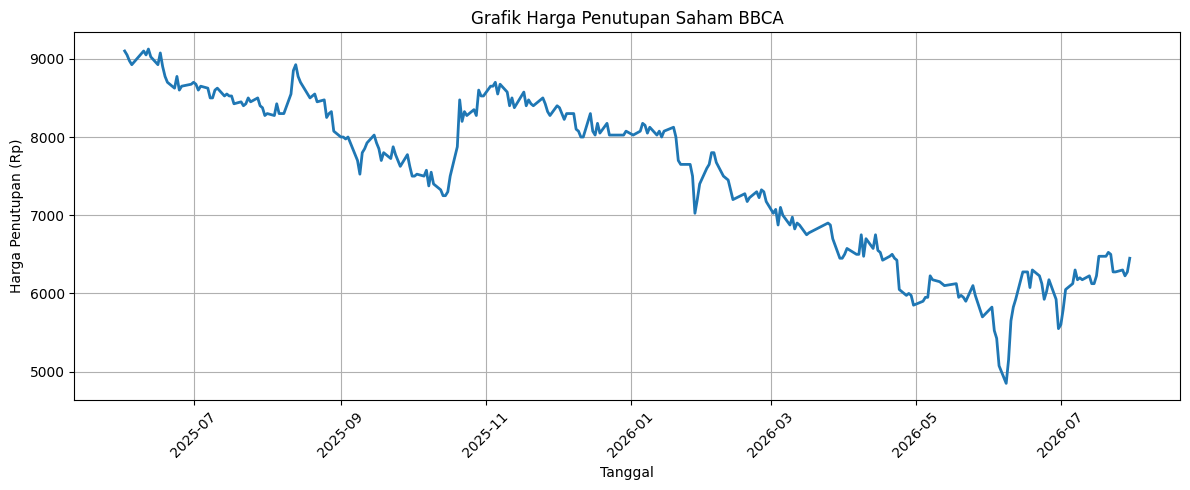

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt

ticker = "BBCA.JK"

data = yf.download(
    ticker,
    start="2025-06-01",
    end="2026-07-31",
    auto_adjust=False
)

data = data[['Close']]

# Mengubah MultiIndex menjadi kolom biasa
data.columns = ['Close']

data.dropna(inplace=True)

print("Jumlah data :", len(data))

display(data.head())
display(data.tail())

# Menampilkan grafik harga penutupan
plt.figure(figsize=(12,5))
plt.plot(data.index, data["Close"], linewidth=2)

plt.title("Grafik Harga Penutupan Saham BBCA")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Rp)")
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

note : Grafik ini menunjukkan pergerakan harga penutupan saham BBCA sepanjang periode pengamatan. Sumbu horizontal menunjukkan tanggal, sedangkan sumbu vertikal menunjukkan harga saham dalam rupiah. Grafik ini masih merupakan data aktual dan belum merupakan hasil prediksi.

PREPROCESSING DATASET

note : Setelah memperoleh harga Close, saya menghitung log return. Rumusnya adalah logaritma natural dari perbandingan harga saat ini dengan harga sebelumnya. Dengan demikian, yang digunakan dalam pemodelan adalah perubahan relatif harga dari satu periode ke periode berikutnya. Log return dipilih karena dapat merepresentasikan perubahan harga secara relatif dan menghasilkan data yang lebih sesuai untuk pemodelan dinamika perubahan harga menggunakan Neural ODE.

             Close  LogReturn
Date                         
2025-06-03  9050.0  -0.005510
2025-06-04  8975.0  -0.008322
2025-06-05  8925.0  -0.005587
2025-06-10  9100.0   0.019418
2025-06-11  9050.0  -0.005510


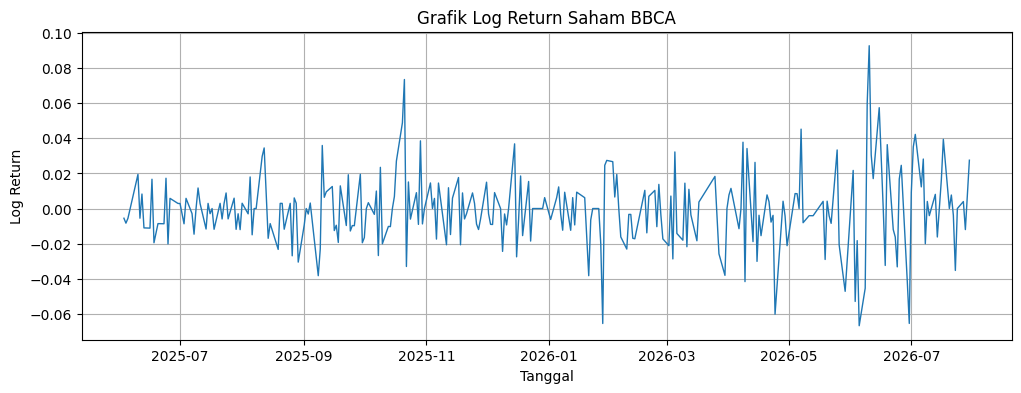

In [ ]:
data["LogReturn"] = np.log(
    data["Close"] / data["Close"].shift(1)
)

data.dropna(inplace=True)

print(data.head())

plt.figure(figsize=(12,4))

plt.plot(
    data.index,
    data["LogReturn"],
    linewidth=1
)

plt.title("Grafik Log Return Saham BBCA")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.grid(True)

plt.show()

note : Grafik ini menunjukkan pergerakan log return. Nilai positif menunjukkan return positif atau kenaikan relatif harga, sedangkan nilai negatif menunjukkan penurunan relatif harga. Grafik ini digunakan untuk melihat dinamika perubahan harga yang kemudian menjadi input pemodelan

DEFINISI NEURAL ODE

In [ ]:
# Fungsi Neural ODE untuk mempelajari f(y)
class ODEFunc(nn.Module):

    def __init__(self):
        # Mengaktifkan fitur neural network PyTorch
        super().__init__()

        # Arsitektur jaringan untuk mempelajari f(y)
        self.net = nn.Sequential(
            nn.Linear(1,64),   # 1 state → 64 neuron
            nn.Tanh(),         # Fungsi aktivasi
            nn.Linear(64,1)    # 64 neuron → 1 output f(y)
        )

    # Menghasilkan turunan f(y) dari state y
    def forward(self, t, y):
        return self.net(y)


print("Model Neural ODE berhasil dibuat.")

Model Neural ODE berhasil dibuat.


note : Kenapa 1,64,1 ?
Karena variabel keadaan yang digunakan dalam model hanya satu, sehingga input dan output masing-masing berukuran satu. keadaan yang dimasukkan ke model adalah satu nilai LogReturn pada satu waktu.

Angka 64 digunakan sebagai jumlah neuron pada hidden layer untuk memberikan kapasitas yang cukup bagi jaringan dalam mempelajari hubungan nonlinier antara variabel keadaan \(y\) dan turunannya \(f(y)\). Angka 64 merupakan hyperparameter arsitektur yang ditentukan pada penelitian, bukan jumlah variabel keadaan.

NOTE : model tidak langsung menghitung harga berikutnya, tetapi mempelajari nilai turunannya atau dinamika perubahan y

METODE EULER

In [ ]:
def euler_method(func, y0, t, verbose=False):

    # Menyimpan nilai awal sebagai titik awal
    y = [y0.view(1)]

    # Menentukan step size
    h = t[1] - t[0]

    # Menampilkan proses jika verbose=True
    if verbose:
        print("\n--- PROSES INTERNAL GRADIEN EULER ---")

    # Perhitungan Euler pada setiap langkah waktu
    for i in range(1, len(t)):

        # Menghitung gradien f(y)
        grad = func(None, y[-1].view(1,1))

        # Menampilkan state dan gradien
        if verbose:
            print(
                f"Hari {i} -> "
                f"Input y_{i-1}: {y[-1].item():.8f} | "
                f"Gradien : {grad.item():.8f}"
            )

        # Rumus metode Euler
        # y_(n+1) = y_n + h*f(y_n)
        y_next = y[-1] + h * grad

        y.append(y_next.view(1))

    return torch.stack(y)

note : Neural ODE menghasilkan gradien \(f(y)\), kemudian metode Euler menggunakan gradien tersebut untuk menghitung nilai \(y\) berikutnya secara bertahap.

METODE RK4

In [ ]:
def rk4_method(func, y0, t, verbose=False):

    # Menyimpan nilai awal
    y = [y0.view(1)]

    # Menentukan step size
    h = t[1] - t[0]

    # Menampilkan proses jika verbose=True
    if verbose:
        print("\n--- PROSES INTERNAL KOEFISIEN RK4 ---")

    # Perhitungan RK4 pada setiap langkah waktu
    for i in range(1, len(t)):

        # Mengambil state sebelumnya
        yi = y[-1].view(1,1)

        # Menghitung empat koefisien RK4
        k1 = func(None, yi)
        k2 = func(None, yi + (h/2)*k1)
        k3 = func(None, yi + (h/2)*k2)
        k4 = func(None, yi + h*k3)

        # Menampilkan nilai k1, k2, k3, dan k4
        if verbose:
            print(
                f"Hari {i} -> "
                f"k1={k1.item():.8f} | "
                f"k2={k2.item():.8f} | "
                f"k3={k3.item():.8f} | "
                f"k4={k4.item():.8f}"
            )

        # Rumus metode RK4
        y_next = yi + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

        y.append(y_next.view(1))

    return torch.stack(y)

Berbeda dengan Euler yang hanya menggunakan satu gradient, RK4 menggunakan empat gradient yaitu \(k_1,k_2,k_3,k_4\). Keempat gradient tersebut kemudian digabungkan menggunakan bobot tertentu untuk mendapatkan nilai berikutnya.

### **VALIDASI MANUAL**

MENYIAPKAN DATA VALIDASI MANUAL

In [ ]:
# ==========================================================
# PERSIAPAN VALIDASI MANUAL
# ==========================================================

# Menentukan tanggal prediksi dan jumlah data historis
tanggal_prediksi = "2026-06-29"
jumlah_hari = 5

# Mencari posisi tanggal prediksi
idx = data.index.get_loc(tanggal_prediksi)

# Mengambil 5 hari data historis
data_input = data.iloc[idx-jumlah_hari:idx].copy()

# Mengambil 5 hari data aktual sebagai pembanding
data_target = data.iloc[idx:idx+5].copy()

# Mengambil harga Close aktual
harga_aktual = data_target["Close"].values.flatten()

# Mengambil harga terakhir sebagai harga awal (P0) #prediksi dimulai dari kondisi terakhir yang diketahui
P0 = data_input["Close"].iloc[-1].item()

# ==========================================================
# STANDARDISASI
# ==========================================================

# Membuat scaler untuk standardisasi LogReturn
scaler = StandardScaler()

# Menghitung mean dan standar deviasi
scaler.fit(data_input[["LogReturn"]])

# Mengubah LogReturn ke skala standar
train_scaled = scaler.transform(data_input[["LogReturn"]])

# Mengubah data menjadi tensor PyTorch
train_tensor = torch.tensor(
    train_scaled,
    dtype=torch.float32
).to(device)


# ==========================================================
# DATA AWAL PREDIKSI
# ==========================================================

# Mengambil LogReturn terakhir sebagai kondisi awal #y0_raw dipertahankan dalam skala asli untuk kebutuhan informasi awal
y0_raw = data_input["LogReturn"].iloc[-1].item()

# Menstandardisasi kondisi awal
y0_scaled = scaler.transform(
    np.array([[y0_raw]])
)[0, 0]

# Mengubah kondisi awal menjadi tensor
test_tensor = torch.tensor(
    [y0_scaled],
    dtype=torch.float32
).to(device)


# ==========================================================
# INFORMASI DATA
# ==========================================================

print("Persiapan validasi manual selesai.")
print()

print(
    "Data historis :",
    data_input.index[0].date(),
    "sampai",
    data_input.index[-1].date()
)

print(
    "Data target   :",
    data_target.index[0].date(),
    "sampai",
    data_target.index[-1].date()
)

Persiapan validasi manual selesai.

Data historis : 2026-06-22 sampai 2026-06-26
Data target   : 2026-06-29 sampai 2026-07-03


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


TRAINING NEURAL  ODE (VALIDASI MANUAL)

note : Setelah data siap, model dilatih menggunakan optimizer Adam dengan learning rate 0,01 dan fungsi loss MSE. Training dilakukan sebanyak 300 epoch. Pada setiap iterasi, Neural ODE digunakan untuk menghasilkan solusi, kemudian hasilnya dibandingkan dengan data training menggunakan MSE. Gradient dihitung melalui backward, kemudian parameter model diperbarui menggunakan Adam.

Training selesai.
Loss Awal  : 0.612110
Loss Akhir : 0.823327


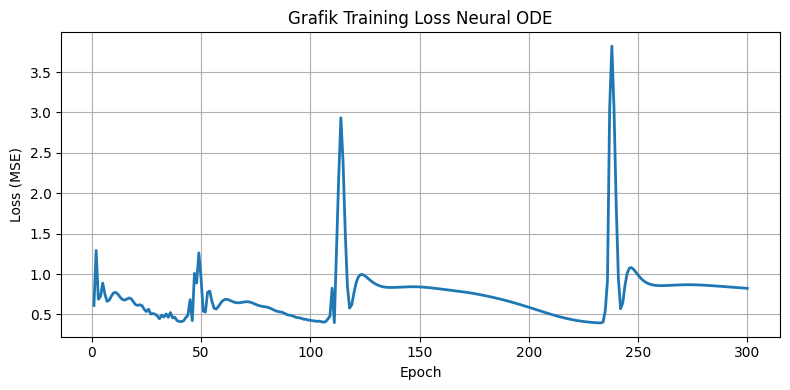

In [ ]:
# Agar bobot awal selalu sama

set_seed(42)

# Membuat model

func = ODEFunc().to(device)

# Menentukan Adam sebagai optimizer untuk memperbarui bobot model.
# Learning rate 0.01 menentukan besar langkah pembaruan bobot.
optimizer = torch.optim.Adam(
    func.parameters(),
    lr=0.01
)
# MSE sebagai fungsi loss untuk mengukur selisih antara hasil prediksi model dan data training.
loss_fn = nn.MSELoss()

# Membuat urutan waktu untuk proses penyelesaian Neural ODE.

t_train = torch.arange(
    len(train_tensor),
    dtype=torch.float32
).to(device)

# Training

epochs = 300

loss_history = [] # Menyimpan nilai loss pada setiap epoch untuk melihat perkembangan training.

for epoch in range(epochs):

    optimizer.zero_grad() # Menghapus gradient dari proses sebelumnya.

# Menghitung solusi Neural ODE menggunakan fungsi odeint.
    pred = odeint(
        func,
        train_tensor[0],
        t_train
    )
# Menghitung nilai loss antara hasil prediksi dan data training.
    loss = loss_fn(
        pred.squeeze(),
        train_tensor.squeeze()
    )
# Menghitung gradient berdasarkan nilai loss.
    loss.backward()
# Memperbarui bobot model menggunakan optimizer Adam.
    optimizer.step()

    loss_history.append(loss.item())

print("Training selesai.")

print(f"Loss Awal  : {loss_history[0]:.6f}")
print(f"Loss Akhir : {loss_history[-1]:.6f}")

# Menampilkan grafik loss
plt.figure(figsize=(8,4))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    linewidth=2
)

plt.title("Grafik Training Loss Neural ODE")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.grid(True)

plt.tight_layout()
plt.show()

note : loss yang ditampilkan adalah loss awal dan loss akhir dari proses training khusus validasi manual. Hasilnya tidak menunjukkan penurunan monoton. Validasi manual ini digunakan untuk memeriksa proses perhitungan Euler dan RK4, sedangkan evaluasi utama penelitian dilihat dari hasil prediksi dan metrik error.

VALIDASI MANUAL

In [ ]:
print("="*70)
print("VALIDASI MANUAL NEURAL ODE")
print("="*70)

# ==========================================================
# Informasi Standardisasi
# ==========================================================
# Mengambil mean (μ) dan standar deviasi (σ) dari scaler.
# Nilai ini digunakan untuk proses standardisasi dan mengembalikan data scaled ke skala LogReturn asli.
mu = scaler.mean_[0]
sigma = scaler.scale_[0]

print(f"Mean (μ)               : {mu:.8f}")
print(f"Standar Deviasi (σ)    : {sigma:.8f}")
print()

print(f"Harga Awal (P0)        : Rp {P0:,.2f}")
print(f"Log Return Awal        : {y0_raw:.8f}")
print(f"Log Return Scaled      : {y0_scaled:.8f}")

# ==========================================================
# Gradien awal Neural ODE
# ==========================================================
# Menggunakan model yang sudah dilatih untuk menghitung gradien awal f(y0) pada kondisi awal y0_scaled.
# Gradien ini digunakan dalam perhitungan Euler dan RK4.
func.eval()

with torch.no_grad():

    grad_awal = func(
        None,
        test_tensor.view(1,1)
    ).item()

print(f"Gradien Awal f(y0)     : {grad_awal:.8f}")

# ==========================================================
# Titik Evaluasi
# ==========================================================
# Menentukan 5 titik waktu untuk proses prediksi.
# Selisih antar titik merupakan step size (h).
t_eval = torch.arange(
    0,
    5,
    1,
    dtype=torch.float32
).to(device)

print(f"Step Size (h)          : {(t_eval[1]-t_eval[0]).item():.1f}")
#h = 1 dan digunakan pada perhitungan Euler maupun RK4.

# ==========================================================
# Prediksi Euler dan RK4
# model yang sudah dilatih digunakan untuk melakukan prediksi menggunakan dua metode numerik.
# ==========================================================

with torch.no_grad(): #tahap prediksi tidak diperlukan perhitungan gradient untuk memperbarui parameter.

    y_pred_euler_scaled = euler_method(
        func,
        test_tensor,
        t_eval,
        verbose=True           #menampilkan proses perhitungan Euler
    )

    y_pred_rk4_scaled = rk4_method(
        func,
        test_tensor,
        t_eval,
        verbose=True          ##menampilkan proses perhitungan RK4
    )

# ==========================================================
# HASIL STANDARDISASI
# ==========================================================
# Menampilkan hasil prediksi Euler yang masih dalam skala standardisasi.
print()
print("="*70)
print("HASIL NORMALISASI")
print("="*70)

print("Euler")

for i, nilai in enumerate(y_pred_euler_scaled.squeeze().cpu().numpy()):
    print(f"y{i} = {nilai:.8f}")

print()

print("RK4")

for i, nilai in enumerate(y_pred_rk4_scaled.squeeze().cpu().numpy()):
    print(f"y{i} = {nilai:.8f}")

# ==========================================================
# INVERSE STANDARD SCALER
# ==========================================================
# Mengembalikan hasil prediksi dari skala standar ke skala LogReturn asli
# menggunakan inverse transform StandardScaler:
# x = z * sigma + mu
log_euler = scaler.inverse_transform(
    y_pred_euler_scaled.cpu().numpy().reshape(-1,1)
).flatten()

log_rk4 = scaler.inverse_transform(
    y_pred_rk4_scaled.cpu().numpy().reshape(-1,1)
).flatten()

print()
print("="*70)
print("HASIL LOG RETURN")
print("="*70)

print("Euler")
# Hasil prediksi Euler setelah dikembalikan ke skala LogReturn.
for i, nilai in enumerate(log_euler):
    print(f"r{i} = {nilai:.8f}")

print()

print("RK4")
# Hasil prediksi RK4 setelah dikembalikan ke skala LogReturn.
for i, nilai in enumerate(log_rk4):
    print(f"r{i} = {nilai:.8f}")

# ==========================================================
# KONVERSI KE HARGA SAHAM
# ==========================================================
# menggunakan inverse transform LogReturn: # P_t = P_0 * exp(r_t)
harga_pred_euler = P0 * np.exp(log_euler)
harga_pred_rk4 = P0 * np.exp(log_rk4)

print()
print("="*70)
print("HASIL KONVERSI KE HARGA SAHAM")
print("="*70)

print("Hari | Euler (Rp) | RK4 (Rp) | Aktual (Rp)")
print("-"*75)
# Membandingkan hasil prediksi Euler dan RK4 dengan
for i in range(len(harga_aktual)):
    print(
        f"{i+1:>4} | "
        f"{harga_pred_euler[i]:>12,.2f} | "
        f"{harga_pred_rk4[i]:>10,.2f} | "
        f"{harga_aktual[i]:>10,.2f}"
    )

print()
print("Validasi manual selesai.")
print("Seluruh nilai di atas dapat digunakan untuk perhitungan manual Euler dan RK4.")

VALIDASI MANUAL NEURAL ODE
Mean (μ)               : -0.00400815
Standar Deviasi (σ)    : 0.02150507

Harga Awal (P0)        : Rp 6,175.00
Log Return Awal        : 0.02459140
Log Return Scaled      : 1.32989828
Gradien Awal f(y0)     : -0.60795695
Step Size (h)          : 1.0

--- PROSES INTERNAL GRADIEN EULER ---
Hari 1 -> Input y_0: 1.32989824 | Gradien : -0.60795695
Hari 2 -> Input y_1: 0.72194129 | Gradien : -0.19878551
Hari 3 -> Input y_2: 0.52315581 | Gradien : -0.06405399
Hari 4 -> Input y_3: 0.45910183 | Gradien : -0.02129701

--- PROSES INTERNAL KOEFISIEN RK4 ---
Hari 1 -> k1=-0.60795695 | k2=-0.40663782 | k3=-0.47454846 | k4=-0.29014224
Hari 2 -> k1=-0.31147572 | k2=-0.20480466 | k3=-0.24130481 | k4=-0.14646703
Hari 3 -> k1=-0.15753719 | k2=-0.10412344 | k3=-0.12218770 | k4=-0.07487146
Hari 4 -> k1=-0.08026028 | k2=-0.05333821 | k3=-0.06235292 | k4=-0.03849300

HASIL NORMALISASI
Euler
y0 = 1.32989824
y1 = 0.72194129
y2 = 0.52315581
y3 = 0.45910183
y4 = 0.43780482

RK4
y0 = 1.3

### **EKSPERIMEN**

FUNGSI EKSPERIMEN

In [ ]:
def prediksi_model(jumlah_hari):

    print("=" * 70)
    print(f"RENTANG HISTORIS : {jumlah_hari} HARI")
    print("=" * 70)

    # ============================================================
    # DATA HISTORIS
    # ============================================================

    # Menentukan posisi tanggal prediksi
    idx = data.index.get_loc(tanggal_prediksi)

    # Mengambil data historis sesuai jumlah hari
    data_input = data.iloc[idx-jumlah_hari:idx].copy()

    # Mengambil 5 hari berikutnya sebagai data aktual
    data_target = data.iloc[idx:idx+5].copy()

    # Mengambil harga Close aktual
    harga_aktual = data_target["Close"].values.flatten()

    # Harga terakhir sebagai harga awal P0
    P0 = data_input["Close"].iloc[-1].item()


    # ============================================================
    # STANDARDISASI
    # ============================================================

    # Membuat scaler untuk standardisasi LogReturn
    scaler = StandardScaler()

    # Menghitung mean dan standar deviasi
    scaler.fit(data_input[["LogReturn"]])

    # Mengubah LogReturn ke skala standar
    train_scaled = scaler.transform(
        data_input[["LogReturn"]]
    )

    # Mengubah data menjadi tensor PyTorch
    train_tensor = torch.tensor(
        train_scaled,
        dtype=torch.float32
    ).to(device)

    # Mengambil LogReturn terakhir sebagai kondisi awal
    y0_raw = data_input["LogReturn"].iloc[-1].item()

    # Menstandardisasi kondisi awal
    y0_scaled = scaler.transform(
        np.array([[y0_raw]])
    )[0, 0]

    # Mengubah kondisi awal menjadi tensor
    test_tensor = torch.tensor(
        [y0_scaled],
        dtype=torch.float32
    ).to(device)


    # ============================================================
    # TRAINING NEURAL ODE
    # ============================================================

    set_seed(42)

    # Membuat model Neural ODE
    func = ODEFunc().to(device)

    # Optimizer untuk memperbarui parameter model
    optimizer = torch.optim.Adam(
        func.parameters(),
        lr=0.01
    )

    # Fungsi loss
    loss_fn = nn.MSELoss()

    # Titik waktu training
    t_train = torch.arange(
        len(train_tensor),
        dtype=torch.float32
    ).to(device)

    # Training selama 300 epoch
    for _ in range(300):

        optimizer.zero_grad()

        # Menyelesaikan Neural ODE
        pred = odeint(
            func,
            train_tensor[0],
            t_train,
            method="rk4"
        )

        # Menghitung loss
        loss = loss_fn(
            pred.squeeze(),
            train_tensor.squeeze()
        )

        # Menghitung gradient dan memperbarui parameter
        loss.backward()
        optimizer.step()


    # ============================================================
    # PREDIKSI
    # ============================================================

    # Membuat 5 titik waktu untuk prediksi
    t_eval = torch.arange(
        0,
        5,
        1,
        dtype=torch.float32
    ).to(device)

    # Melakukan prediksi tanpa menghitung gradient
    with torch.no_grad():

        # Prediksi dengan Euler
        y_euler = euler_method(
            func,
            test_tensor,
            t_eval,
            verbose=False
        )

        # Prediksi dengan RK4
        y_rk4 = rk4_method(
            func,
            test_tensor,
            t_eval,
            verbose=False
        )


    # ============================================================
    # DENORMALISASI
    # ============================================================

    # Mengembalikan hasil ke skala LogReturn asli
    log_euler = scaler.inverse_transform(
        y_euler.cpu().numpy().reshape(-1, 1)
    ).flatten()

    log_rk4 = scaler.inverse_transform(
        y_rk4.cpu().numpy().reshape(-1, 1)
    ).flatten()

    # Mengubah LogReturn menjadi harga saham
    harga_euler = P0 * np.exp(log_euler)
    harga_rk4 = P0 * np.exp(log_rk4)


    # ============================================================
    # ERROR
    # ============================================================

    # Menghitung selisih prediksi dengan harga aktual
    error_euler = np.abs(harga_aktual - harga_euler)
    error_rk4 = np.abs(harga_aktual - harga_rk4)

    # MAE
    mae_euler = np.mean(error_euler)
    mae_rk4 = np.mean(error_rk4)

    # RMSE
    rmse_euler = np.sqrt(np.mean(error_euler**2))
    rmse_rk4 = np.sqrt(np.mean(error_rk4**2))

    # MAPE
    mape_euler = np.mean(error_euler / harga_aktual) * 100
    mape_rk4 = np.mean(error_rk4 / harga_aktual) * 100


    # ============================================================
    # TABEL PREDIKSI
    # ============================================================

    hasil_prediksi = pd.DataFrame({

        "Tanggal": data_target.index.strftime("%d-%m-%Y"),

        "Aktual": np.round(harga_aktual, 2),

        "Euler": np.round(harga_euler, 2),

        "RK4": np.round(harga_rk4, 2),

        "Error Euler": np.round(error_euler, 2),

        "Error RK4": np.round(error_rk4, 2)

    })

    print()
    print("HASIL PREDIKSI")
    print("-" * 90)

    display(hasil_prediksi)


    # ============================================================
    # EVALUASI
    # ============================================================

    print()

    print(f"MAE Euler  : {mae_euler:.4f}")
    print(f"RMSE Euler : {rmse_euler:.4f}")
    print(f"MAPE Euler : {mape_euler:.4f}%")

    print()

    print(f"MAE RK4    : {mae_rk4:.4f}")
    print(f"RMSE RK4   : {rmse_rk4:.4f}")
    print(f"MAPE RK4   : {mape_rk4:.4f}%")

    return {

        "Rentang": jumlah_hari,

        "MAE Euler": mae_euler,
        "RMSE Euler": rmse_euler,
        "MAPE Euler": mape_euler,

        "MAE RK4": mae_rk4,
        "RMSE RK4": rmse_rk4,
        "MAPE RK4": mape_rk4,

        "Hasil": hasil_prediksi,

        "Tanggal": data_target.index,

        "Aktual": harga_aktual,

        "Euler": harga_euler,

        "RK4": harga_rk4
    }

PREDIKSI DENGAN RENTANG WAKTU DATA 1 MINGGU

In [ ]:
hasil_1_minggu = prediksi_model(5)

RENTANG HISTORIS : 5 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6414.529785,6416.020020,864.53,866.02
2,01-07-2026,5600.0,6502.899902,6502.180176,902.90,902.19
3,02-07-2026,5800.0,6587.569824,6584.160156,787.57,784.16
4,03-07-2026,6050.0,6667.810059,6662.410156,617.81,612.41



MAE Euler  : 715.3055
RMSE Euler : 738.5893
MAPE Euler : 12.4609%

MAE RK4    : 713.7019
RMSE RK4   : 737.1405
MAPE RK4   : 12.4342%


PREDIKSI DENGAN RENTANG WAKTU DATA 2 MINGGU

In [ ]:
hasil_2_minggu = prediksi_model(10)

RENTANG HISTORIS : 10 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6230.490234,6256.790039,680.49,706.79
2,01-07-2026,5600.0,6196.180176,6219.009766,596.18,619.01
3,02-07-2026,5800.0,6182.770020,6198.600098,382.77,398.60
4,03-07-2026,6050.0,6177.350098,6187.419922,127.35,137.42



MAE Euler  : 438.1060
RMSE Euler : 478.3793
MAPE Euler : 7.6852%

MAE RK4    : 453.1130
RMSE RK4   : 494.6726
MAPE RK4   : 7.9494%


PREDIKSI DENGAN RENTANG WAKTU DATA 1 BULAN

In [ ]:
hasil_1_bulan = prediksi_model(20)

RENTANG HISTORIS : 20 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6146.109863,6232.040039,596.11,682.04
2,01-07-2026,5600.0,6204.810059,6204.140137,604.81,604.14
3,02-07-2026,5800.0,6188.680176,6195.899902,388.68,395.90
4,03-07-2026,6050.0,6193.470215,6193.439941,143.47,143.44



MAE Euler  : 427.3614
RMSE Euler : 459.5219
MAPE Euler : 7.4856%

MAE RK4    : 445.8510
RMSE RK4   : 483.8349
MAPE RK4   : 7.8176%


PREDIKSI DENGAN RENTANG WAKTU DATA 3 BULAN

In [ ]:
hasil_3_bulan = prediksi_model(63)

RENTANG HISTORIS : 63 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6114.319824,6212.609863,564.32,662.61
2,01-07-2026,5600.0,6185.750000,6179.540039,585.75,579.54
3,02-07-2026,5800.0,6159.060059,6170.120117,359.06,370.12
4,03-07-2026,6050.0,6169.100098,6167.430176,119.10,117.43



MAE Euler  : 406.3941
RMSE Euler : 439.9263
MAPE Euler : 7.1202%

MAE RK4    : 426.6879
RMSE RK4   : 466.6272
MAPE RK4   : 7.4849%


PREDIKSI DENGAN RENTANG WAKTU DATA 6 BULAN

In [ ]:
hasil_6_bulan = prediksi_model(126)

RENTANG HISTORIS : 126 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6125.259766,6214.259766,575.26,664.26
2,01-07-2026,5600.0,6181.560059,6180.779785,581.56,580.78
3,02-07-2026,5800.0,6162.140137,6171.080078,362.14,371.08
4,03-07-2026,6050.0,6168.830078,6168.259766,118.83,118.26



MAE Euler  : 408.3053
RMSE Euler : 442.1319
MAPE Euler : 7.1544%

MAE RK4    : 427.6221
RMSE RK4   : 467.5955
MAPE RK4   : 7.5013%


PREDIKSI DENGAN RENTANG WAKTU DATA 1 TAHUN

In [ ]:
hasil_1_tahun = prediksi_model(252)

RENTANG HISTORIS : 252 HARI


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



HASIL PREDIKSI
------------------------------------------------------------------------------------------


,Tanggal,Aktual,Euler,RK4,Error Euler,Error RK4
0,29-06-2026,5925.0,6328.729980,6328.729980,403.73,403.73
1,30-06-2026,5550.0,6142.290039,6223.979980,592.29,673.98
2,01-07-2026,5600.0,6196.410156,6193.740234,596.41,593.74
3,02-07-2026,5800.0,6176.129883,6185.109863,376.13,385.11
4,03-07-2026,6050.0,6183.759766,6182.649902,133.76,132.65



MAE Euler  : 420.4637
RMSE Euler : 453.6243
MAPE Euler : 7.3664%

MAE RK4    : 437.8445
RMSE RK4   : 476.5902
MAPE RK4   : 7.6786%


PERBANDINGAN SEMUA RENTANG HISTORIS

In [ ]:
hasil_semua = pd.DataFrame([

    hasil_1_minggu,
    hasil_2_minggu,
    hasil_1_bulan,
    hasil_3_bulan,
    hasil_6_bulan,
    hasil_1_tahun

])

hasil_semua["Rentang"] = [

    "1 Minggu",
    "2 Minggu",
    "1 Bulan",
    "3 Bulan",
    "6 Bulan",
    "1 Tahun"

]

# Urutan kolom

hasil_semua = hasil_semua[[
    "Rentang",

    "MAE Euler",
    "RMSE Euler",
    "MAPE Euler",

    "MAE RK4",
    "RMSE RK4",
    "MAPE RK4"
]]

print("="*70)
print("PERBANDINGAN HASIL EKSPERIMEN")
print("="*70)

display(hasil_semua)

print()

# Rentang historis terbaik Euler

print("="*70)
print("RENTANG HISTORIS TERBAIK (EULER)")
print("="*70)

best_euler = hasil_semua.loc[
    hasil_semua["MAPE Euler"].idxmin()
]

print(best_euler)

print()

# Rentang historis terbaik RK4

print("="*70)
print("RENTANG HISTORIS TERBAIK (RK4)")
print("="*70)

best_rk4 = hasil_semua.loc[
    hasil_semua["MAPE RK4"].idxmin()
]

print(best_rk4)

print()

# Ringkasan singkat

print("="*70)
print("RINGKASAN")
print("="*70)

print(f"""
Euler
------
Rentang terbaik : {best_euler['Rentang']}
MAE  : {best_euler['MAE Euler']:.4f}
RMSE : {best_euler['RMSE Euler']:.4f}
MAPE : {best_euler['MAPE Euler']:.4f}%

RK4
----
Rentang terbaik : {best_rk4['Rentang']}
MAE  : {best_rk4['MAE RK4']:.4f}
RMSE : {best_rk4['RMSE RK4']:.4f}
MAPE : {best_rk4['MAPE RK4']:.4f}%
""")

PERBANDINGAN HASIL EKSPERIMEN


,Rentang,MAE Euler,RMSE Euler,MAPE Euler,MAE RK4,RMSE RK4,MAPE RK4
0,1 Minggu,715.305469,738.589284,12.460929,713.701855,737.140481,12.434193
1,2 Minggu,438.105957,478.379297,7.685154,453.112988,494.672581,7.949358
2,1 Bulan,427.361426,459.521915,7.485563,445.850977,483.834902,7.817618
3,3 Bulan,406.394141,439.926267,7.120245,426.687891,466.627222,7.484878
4,6 Bulan,408.305273,442.131864,7.154417,427.622070,467.595478,7.501274
5,1 Tahun,420.463672,453.624309,7.366392,437.844531,476.590197,7.678580



RENTANG HISTORIS TERBAIK (EULER)
Rentang          3 Bulan
MAE Euler     406.394141
RMSE Euler    439.926267
MAPE Euler      7.120245
MAE RK4       426.687891
RMSE RK4      466.627222
MAPE RK4        7.484878
Name: 3, dtype: object

RENTANG HISTORIS TERBAIK (RK4)
Rentang          3 Bulan
MAE Euler     406.394141
RMSE Euler    439.926267
MAPE Euler      7.120245
MAE RK4       426.687891
RMSE RK4      466.627222
MAPE RK4        7.484878
Name: 3, dtype: object

RINGKASAN

Euler
------
Rentang terbaik : 3 Bulan
MAE  : 406.3941
RMSE : 439.9263
MAPE : 7.1202%

RK4
----
Rentang terbaik : 3 Bulan
MAE  : 426.6879
RMSE : 466.6272
MAPE : 7.4849%



Grafik prediksi vs aktual rentang terbaik (3 bulan)

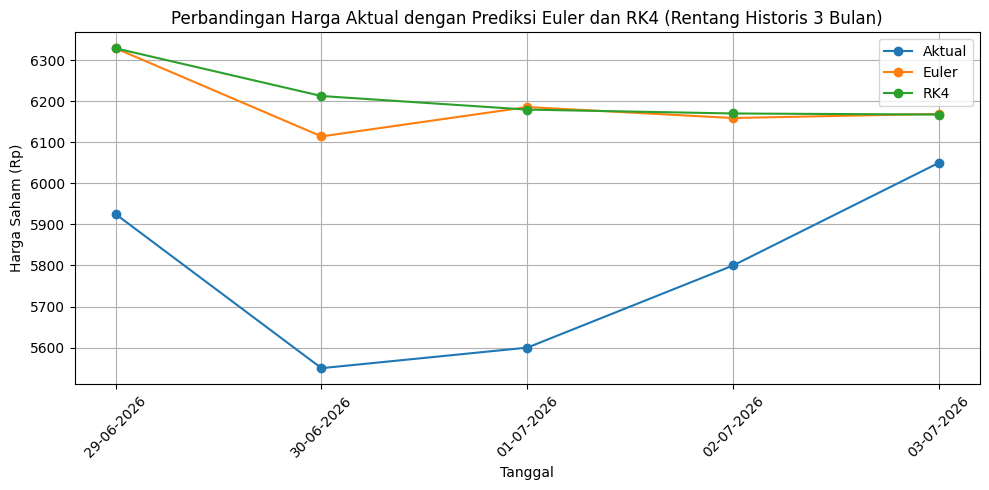

In [ ]:
grafik_3_bulan = hasil_3_bulan["Hasil"]

plt.figure(figsize=(10, 5))

plt.plot(
    grafik_3_bulan["Tanggal"],
    grafik_3_bulan["Aktual"],
    marker="o",
    label="Aktual"
)

plt.plot(
    grafik_3_bulan["Tanggal"],
    grafik_3_bulan["Euler"],
    marker="o",
    label="Euler"
)

plt.plot(
    grafik_3_bulan["Tanggal"],
    grafik_3_bulan["RK4"],
    marker="o",
    label="RK4"
)

plt.title(
    "Perbandingan Harga Aktual dengan Prediksi Euler dan RK4 "
    "(Rentang Historis 3 Bulan)"
)

plt.xlabel("Tanggal")
plt.ylabel("Harga Saham (Rp)")

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

note : Berdasarkan grafik, prediksi Euler dan RK4 menunjukkan pola yang relatif berbeda dari pergerakan harga aktual, terutama ketika harga aktual mengalami penurunan. Berdasarkan hasil evaluasi pada rentang historis 3 bulan, metode Euler menghasilkan MAPE sebesar 7,12%, yang menunjukkan rata-rata kesalahan prediksi sebesar 7,12% terhadap harga aktual. Selain itu, berdasarkan nilai MAE, RMSE, dan MAPE, metode Euler memberikan hasil yang lebih baik dibandingkan RK4 pada pengujian ini.

ANALISIS STABILITAS EULER

note:  model diatur ke mode evaluasi, kemudian diambil nilai awal dari data pengujian untuk menghitung Jacobian menggunakan autograd PyTorch. Nilai Jacobian tersebut digunakan sebagai eigenvalue lokal karena model hanya memiliki satu variabel keadaan. Selanjutnya, program menguji 200 ukuran langkah dari 0 sampai 2 dan menghitung faktor stabilitas dengan rumus \(|1+h\lambda|\). Hasilnya ditampilkan dalam grafik dengan garis batas stabil pada nilai 1. Metode Euler dinyatakan stabil apabila faktor stabilitas kurang dari 1. Terakhir, program menentukan dan menampilkan kesimpulan mengenai rentang ukuran langkah yang memenuhi kriteria stabilitas tersebut

ANALISIS STABILITAS METODE EULER

Eigenvalue lokal (λ) : -0.639948


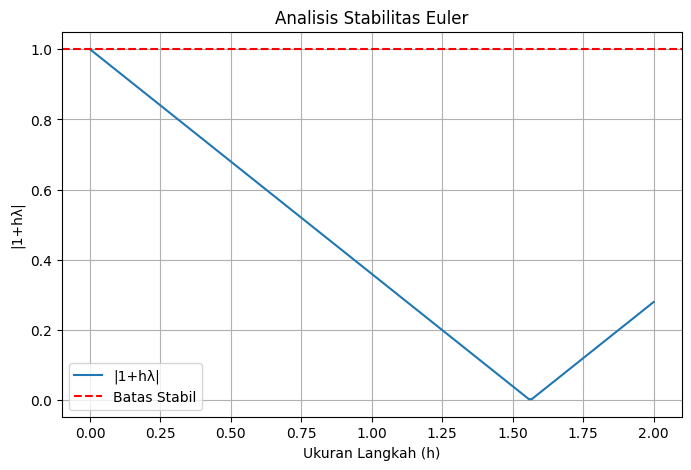


Euler stabil hingga sekitar h < 2.000


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

print("="*60)
print("ANALISIS STABILITAS METODE EULER")
print("="*60)

# Menghitung eigenvalue lokal model Neural ODE
func.eval()

y = test_tensor[0].clone().detach().view(1,1)
y.requires_grad_(True)

f = func(None, y)

jacobian = torch.autograd.grad(
    outputs=f,
    inputs=y,
    grad_outputs=torch.ones_like(f),
    create_graph=False
)[0]

lambda_local = jacobian.item()

print(f"\nEigenvalue lokal (λ) : {lambda_local:.6f}")

# Menghitung faktor stabilitas Euler untuk berbagai ukuran langkah
h = np.linspace(0,2,200)
stability = np.abs(1 + h*lambda_local)

# Menampilkan grafik stabilitas Euler
plt.figure(figsize=(8,5))

plt.plot(h, stability, label="|1+hλ|")

plt.axhline(
    1,
    linestyle="--",
    color="red",
    label="Batas Stabil"
)

plt.xlabel("Ukuran Langkah (h)")
plt.ylabel("|1+hλ|")
plt.title("Analisis Stabilitas Euler")
plt.grid(True)
plt.legend()
plt.show()

# Menentukan kesimpulan stabilitas
if np.all(stability < 1):
    print("\nKesimpulan : Euler stabil pada seluruh rentang h yang diuji.")
else:
    batas = h[np.where(stability < 1)]
    if len(batas) > 0:
        print(f"\nEuler stabil hingga sekitar h < {batas.max():.3f}")
    else:
        print("\nTidak ditemukan daerah stabil pada rentang h yang diuji.")


Note : Grafik ini menunjukkan analisis stabilitas metode Euler pada Neural ODE berdasarkan nilai eigenvalue lokal (\lambda = -0{,}639948). Eigenvalue lokal yang negatif menunjukkan bahwa sistem secara lokal cenderung stabil karena gangguan kecil cenderung mereda. Sumbu X menunjukkan ukuran langkah ((h)), sedangkan sumbu Y menunjukkan faktor amplifikasi (|1+h\lambda|). Berdasarkan teori, metode Euler dinyatakan stabil apabila (|1+h\lambda| < 1), yang ditunjukkan oleh kurva biru berada di bawah garis merah sebagai batas stabilitas. Dari hasil tersebut dapat disimpulkan bahwa ukuran langkah yang digunakan masih berada pada daerah stabil, sehingga metode Euler mampu menghasilkan solusi numerik yang tidak mengalami divergensi atau pertumbuhan galat yang berlebihan selama proses prediksi.


ANALISIS STABILITAS RK4

ANALISIS STABILITAS METODE RK4

Eigenvalue lokal (λ) : -0.639948


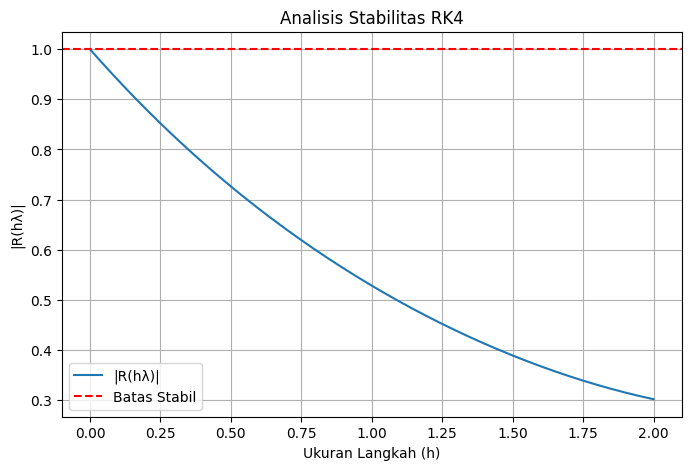


RK4 stabil hingga sekitar h < 2.000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("="*60)
print("ANALISIS STABILITAS METODE RK4")
print("="*60)

# Menggunakan eigenvalue lokal dari model Neural ODE
print(f"\nEigenvalue lokal (λ) : {lambda_local:.6f}")

# Menghitung faktor stabilitas RK4 untuk berbagai ukuran langkah
h = np.linspace(0,2,200)
# Menghitung z = hλ sebagai input polinomial stabilitas RK4
z = h * lambda_local

#polinomial stabilitas RK4
R = (
    1
    + z
    + (z**2)/2
    + (z**3)/6
    + (z**4)/24
)

stability = np.abs(R)

# Menampilkan grafik stabilitas RK4
plt.figure(figsize=(8,5))

plt.plot(
    h,
    stability,
    label="|R(hλ)|"
)

plt.axhline(
    1,
    color="red",
    linestyle="--",
    label="Batas Stabil"
)

plt.xlabel("Ukuran Langkah (h)")
plt.ylabel("|R(hλ)|")
plt.title("Analisis Stabilitas RK4")
plt.grid(True)
plt.legend()
plt.show()

# Menentukan kesimpulan stabilitas
if np.all(stability < 1):
    print("\nKesimpulan : RK4 stabil pada seluruh rentang h yang diuji.")
else:
    batas = h[np.where(stability < 1)]
    if len(batas) > 0:
        print(f"\nRK4 stabil hingga sekitar h < {batas.max():.3f}")
    else:
        print("\nTidak ditemukan daerah stabil pada rentang h yang diuji.")

Note : Berdasarkan grafik, metode RK4 berada dalam kondisi stabil pada seluruh ukuran langkah yang diuji, yaitu sampai h = 2. Nilai faktor stabilitas selalu berada di bawah 1. Dengan eigenvalue lokal sebesar -0,639948, hasil ini menunjukkan bahwa RK4 mampu mempertahankan kestabilan numerik pada rentang ukuran langkah tersebut.

Pengaruh Ukuran Langkah (Step Size) terhadap Galat Numerik

PENGARUH UKURAN LANGKAH (STEP SIZE)



,Jumlah Step,Step Size (h),Error Euler,Error RK4
0,5,0.250000,0.028443,2.086163e-06
1,10,0.111111,0.012028,5.960464e-07
2,20,0.052632,0.005585,6.556511e-07
3,40,0.025641,0.002697,7.748604e-07
4,80,0.012658,0.001326,5.364418e-07
5,160,0.006289,0.000658,7.152557e-07


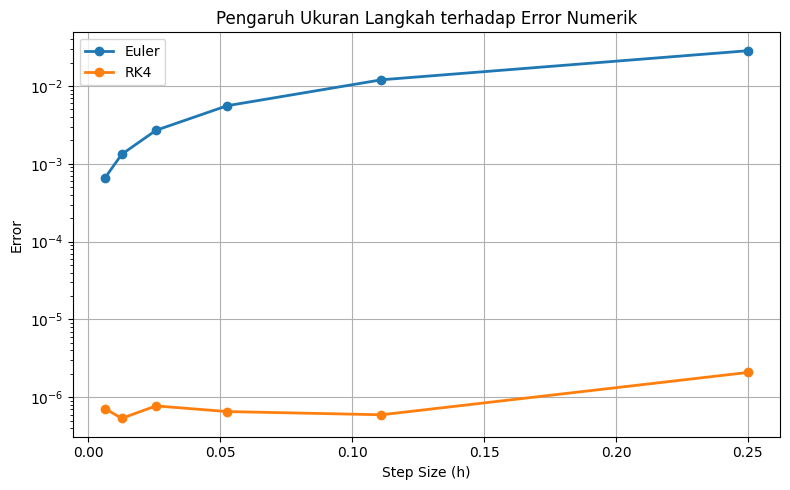

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("="*60)
print("PENGARUH UKURAN LANGKAH (STEP SIZE)")
print("="*60)


# ============================================================
# SOLUSI REFERENSI
# ============================================================

# Membuat solusi referensi dengan RK4 dan step sangat kecil.
# Solusi ini digunakan sebagai acuan untuk menghitung error.
t_ref = torch.linspace(0, 1, 1001).to(device)

with torch.no_grad():

    # Mengambil nilai akhir sebagai solusi referensi
    y_ref = rk4_method(
        func,
        test_tensor[0],
        t_ref,
        verbose=False
    )[-1]


# ============================================================
# VARIASI JUMLAH LANGKAH
# ============================================================

# Menentukan jumlah step yang akan diuji.
step_list = [5, 10, 20, 40, 80, 160]

# Menyimpan hasil pengujian
hasil = []

# Menguji Euler dan RK4 pada setiap jumlah step
for n in step_list:

    # Membagi interval waktu menjadi n titik.
    # Semakin banyak step, semakin kecil ukuran langkah (h).
    t = torch.linspace(0, 1, n).to(device)

    # Menghitung ukuran langkah yang digunakan
    h = (t[1] - t[0]).item()

    with torch.no_grad():

        # Menghitung solusi dengan metode Euler
        y_euler = euler_method(
            func,
            test_tensor[0],
            t,
            verbose=False
        )[-1]

        # Menghitung solusi dengan metode RK4
        y_rk4 = rk4_method(
            func,
            test_tensor[0],
            t,
            verbose=False
        )[-1]

    # Menghitung error terhadap solusi referensi.
    # Error yang lebih kecil menunjukkan hasil yang lebih mendekati acuan.
    error_euler = torch.abs(y_euler - y_ref).item()
    error_rk4 = torch.abs(y_rk4 - y_ref).item()

    # Menyimpan jumlah step, h, dan error
    hasil.append([
        n,
        h,
        error_euler,
        error_rk4
    ])


# ============================================================
# TABEL HASIL
# ============================================================

# Membuat tabel hasil pengujian
df_step = pd.DataFrame(
    hasil,
    columns=[
        "Jumlah Step",
        "Step Size (h)",
        "Error Euler",
        "Error RK4"
    ]
)

print()
display(df_step)


# ============================================================
# GRAFIK
# ============================================================

plt.figure(figsize=(8, 5))

# Grafik error Euler terhadap step size
plt.plot(
    df_step["Step Size (h)"],
    df_step["Error Euler"],
    marker="o",
    linewidth=2,
    label="Euler"
)

# Grafik error RK4 terhadap step size
plt.plot(
    df_step["Step Size (h)"],
    df_step["Error RK4"],
    marker="o",
    linewidth=2,
    label="RK4"
)

plt.xlabel("Step Size (h)")
plt.ylabel("Error")

plt.title(
    "Pengaruh Ukuran Langkah terhadap Error Numerik"
)

# Skala logaritmik agar perbedaan error lebih mudah terlihat
plt.yscale("log")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Note :

Grafik menunjukkan bahwa semakin kecil ukuran langkah, error numerik metode Euler semakin kecil. Sebaliknya, metode RK4 menghasilkan error yang jauh lebih kecil dan relatif stabil pada seluruh ukuran langkah yang diuji. Dengan demikian, berdasarkan pengujian ini, RK4 memiliki ketelitian numerik yang lebih tinggi dibandingkan Euler dalam menyelesaikan persamaan Neural ODE

KESIMPULAN ANALISIS NUMERIK

In [ ]:
# =====================================================
# KESIMPULAN ANALISIS NUMERIK (OTOMATIS)
# =====================================================

print("="*70)
print("KESIMPULAN ANALISIS NUMERIK")
print("="*70)

# -----------------------------------------------------
# Menentukan metode dengan error numerik terkecil
# -----------------------------------------------------

rata_error_euler = df_step["Error Euler"].mean()
rata_error_rk4 = df_step["Error RK4"].mean()

if rata_error_euler < rata_error_rk4:
    metode_terbaik = "Euler"
else:
    metode_terbaik = "RK4"

# -----------------------------------------------------
# Menentukan rentang historis terbaik
# -----------------------------------------------------

best_euler = hasil_semua.loc[
    hasil_semua["MAPE Euler"].idxmin()
]

best_rk4 = hasil_semua.loc[
    hasil_semua["MAPE RK4"].idxmin()
]

# -----------------------------------------------------
# Menampilkan kesimpulan
# -----------------------------------------------------

print()

print("1. Analisis Stabilitas")

print(
    f"   Eigenvalue lokal (λ) = {lambda_local:.6f}"
)

if lambda_local < 0:
    print("   Nilai eigenvalue negatif menunjukkan model bersifat stabil di sekitar titik evaluasi.")
else:
    print("   Nilai eigenvalue positif menunjukkan model kurang stabil di sekitar titik evaluasi.")

print()

print("2. Analisis Error Numerik")

print(f"   Rata-rata Error Euler : {rata_error_euler:.8f}")
print(f"   Rata-rata Error RK4   : {rata_error_rk4:.8f}")

print()

print(f"   Metode dengan error numerik paling kecil adalah {metode_terbaik}.")

print()

print("3. Analisis Rentang Historis Terbaik")

print(f"""
Euler
------
Rentang : {best_euler['Rentang']}
MAE     : {best_euler['MAE Euler']:.4f}
RMSE    : {best_euler['RMSE Euler']:.4f}
MAPE    : {best_euler['MAPE Euler']:.4f}%

RK4
----
Rentang : {best_rk4['Rentang']}
MAE     : {best_rk4['MAE RK4']:.4f}
RMSE    : {best_rk4['RMSE RK4']:.4f}
MAPE    : {best_rk4['MAPE RK4']:.4f}%
""")

print("4. Kesimpulan Akhir")

print(
    "Model Neural ODE berhasil digunakan untuk memodelkan harga saham BBCA. "
    "Berdasarkan analisis stabilitas, model memiliki eigenvalue lokal bernilai negatif sehingga bersifat stabil di sekitar titik evaluasi. "
    f"Pada analisis ukuran langkah, metode {metode_terbaik} menghasilkan error numerik paling kecil. "
    f"Pada eksperimen prediksi menggunakan berbagai rentang historis, performa terbaik diperoleh pada rentang historis {best_euler['Rentang']}. "
    f"Pada rentang tersebut, metode Euler menghasilkan MAE sebesar {best_euler['MAE Euler']:.4f}, "
    f"RMSE sebesar {best_euler['RMSE Euler']:.4f}, "
    f"dan MAPE sebesar {best_euler['MAPE Euler']:.4f}%."
)

KESIMPULAN ANALISIS NUMERIK

1. Analisis Stabilitas
   Eigenvalue lokal (λ) = -0.639948
   Nilai eigenvalue negatif menunjukkan model bersifat stabil di sekitar titik evaluasi.

2. Analisis Error Numerik
   Rata-rata Error Euler : 0.00845630
   Rata-rata Error RK4   : 0.00000089

   Metode dengan error numerik paling kecil adalah RK4.

3. Analisis Rentang Historis Terbaik

Euler
------
Rentang : 3 Bulan
MAE     : 406.3941
RMSE    : 439.9263
MAPE    : 7.1202%

RK4
----
Rentang : 3 Bulan
MAE     : 426.6879
RMSE    : 466.6272
MAPE    : 7.4849%

4. Kesimpulan Akhir
Model Neural ODE berhasil digunakan untuk memodelkan harga saham BBCA. Berdasarkan analisis stabilitas, model memiliki eigenvalue lokal bernilai negatif sehingga bersifat stabil di sekitar titik evaluasi. Pada analisis ukuran langkah, metode RK4 menghasilkan error numerik paling kecil. Pada eksperimen prediksi menggunakan berbagai rentang historis, performa terbaik diperoleh pada rentang historis 3 Bulan. Pada rentang tersebut, 

RINGKASAN HASIL PENELITIAN

In [ ]:
# =====================================================
# RINGKASAN HASIL PENELITIAN
# =====================================================

import pandas as pd

print("="*70)
print("RINGKASAN HASIL PENELITIAN")
print("="*70)

# =====================================================
# MENENTUKAN RENTANG TERBAIK BERDASARKAN 3 METRIK
# =====================================================

ranking_euler = hasil_semua.copy()

ranking_euler["Rank MAE"] = ranking_euler["MAE Euler"].rank(method="min")
ranking_euler["Rank RMSE"] = ranking_euler["RMSE Euler"].rank(method="min")
ranking_euler["Rank MAPE"] = ranking_euler["MAPE Euler"].rank(method="min")

ranking_euler["Total Rank"] = (
    ranking_euler["Rank MAE"] +
    ranking_euler["Rank RMSE"] +
    ranking_euler["Rank MAPE"]
)

best_euler = ranking_euler.loc[
    ranking_euler["Total Rank"].idxmin()
]

# =====================================================

ranking_rk4 = hasil_semua.copy()

ranking_rk4["Rank MAE"] = ranking_rk4["MAE RK4"].rank(method="min")
ranking_rk4["Rank RMSE"] = ranking_rk4["RMSE RK4"].rank(method="min")
ranking_rk4["Rank MAPE"] = ranking_rk4["MAPE RK4"].rank(method="min")

ranking_rk4["Total Rank"] = (
    ranking_rk4["Rank MAE"] +
    ranking_rk4["Rank RMSE"] +
    ranking_rk4["Rank MAPE"]
)

best_rk4 = ranking_rk4.loc[
    ranking_rk4["Total Rank"].idxmin()
]

# =====================================================
# ERROR NUMERIK
# =====================================================

avg_error_euler = df_step["Error Euler"].mean()
avg_error_rk4 = df_step["Error RK4"].mean()

if avg_error_euler < avg_error_rk4:
    metode_terbaik = "Euler"
else:
    metode_terbaik = "RK4"

# =====================================================
# TABEL RINGKASAN
# =====================================================

ringkasan = pd.DataFrame({

    "Parameter":[

        "Dataset",

        "Model",

        "Metode Terbaik (Error Numerik)",

        "Eigenvalue Lokal",

        "Rata-rata Error Euler",

        "Rata-rata Error RK4",

        "Rentang Historis Terbaik (Euler)",

        "MAE Euler",

        "RMSE Euler",

        "MAPE Euler",

        "Rentang Historis Terbaik (RK4)",

        "MAE RK4",

        "RMSE RK4",

        "MAPE RK4"

    ],

    "Hasil":[

        "BBCA.JK",

        "Neural ODE",

        metode_terbaik,

        f"{lambda_local:.6f}",

        f"{avg_error_euler:.8f}",

        f"{avg_error_rk4:.8f}",

        best_euler["Rentang"],

        f"{best_euler['MAE Euler']:.4f}",

        f"{best_euler['RMSE Euler']:.4f}",

        f"{best_euler['MAPE Euler']:.4f}%",

        best_rk4["Rentang"],

        f"{best_rk4['MAE RK4']:.4f}",

        f"{best_rk4['RMSE RK4']:.4f}",

        f"{best_rk4['MAPE RK4']:.4f}%"

    ]

})

display(ringkasan)

print()

print("="*70)
print("KESIMPULAN")
print("="*70)

print(f"""
1. Model Neural ODE berhasil digunakan untuk memodelkan harga saham BBCA.

2. Nilai eigenvalue lokal sebesar {lambda_local:.6f}
   bernilai negatif sehingga menunjukkan bahwa model
   memiliki karakteristik stabil di sekitar titik evaluasi.

3. Berdasarkan analisis error numerik pada pengujian
   ukuran langkah (step size), metode {metode_terbaik}
   menghasilkan rata-rata error numerik paling kecil.

4. Pada eksperimen prediksi menggunakan beberapa
   rentang historis, performa terbaik diperoleh pada
   rentang historis {best_euler['Rentang']}.

5. Pada rentang historis tersebut, metode Euler
   menghasilkan:
   MAE  = {best_euler['MAE Euler']:.4f}
   RMSE = {best_euler['RMSE Euler']:.4f}
   MAPE = {best_euler['MAPE Euler']:.4f}%.

6. Secara keseluruhan, model Neural ODE mampu digunakan
   untuk memprediksi harga saham BBCA dengan baik.
   Metode RK4 memberikan error numerik paling kecil
   pada analisis ukuran langkah, sedangkan metode
   Euler menghasilkan akurasi prediksi terbaik pada
   dataset penelitian ini.
""")

RINGKASAN HASIL PENELITIAN


,Parameter,Hasil
0,Dataset,BBCA.JK
1,Model,Neural ODE
2,Metode Terbaik (Error Numerik),RK4
3,Eigenvalue Lokal,-0.639948
4,Rata-rata Error Euler,0.00845630
5,Rata-rata Error RK4,0.00000089
6,Rentang Historis Terbaik (Euler),3 Bulan
7,MAE Euler,406.3941
8,RMSE Euler,439.9263
9,MAPE Euler,7.1202%



KESIMPULAN

1. Model Neural ODE berhasil digunakan untuk memodelkan harga saham BBCA.

2. Nilai eigenvalue lokal sebesar -0.639948
   bernilai negatif sehingga menunjukkan bahwa model
   memiliki karakteristik stabil di sekitar titik evaluasi.

3. Berdasarkan analisis error numerik pada pengujian
   ukuran langkah (step size), metode RK4
   menghasilkan rata-rata error numerik paling kecil.

4. Pada eksperimen prediksi menggunakan beberapa
   rentang historis, performa terbaik diperoleh pada
   rentang historis 3 Bulan.

5. Pada rentang historis tersebut, metode Euler
   menghasilkan:
   MAE  = 406.3941
   RMSE = 439.9263
   MAPE = 7.1202%.

6. Secara keseluruhan, model Neural ODE mampu digunakan
   untuk memprediksi harga saham BBCA dengan baik.
   Metode RK4 memberikan error numerik paling kecil
   pada analisis ukuran langkah, sedangkan metode
   Euler menghasilkan akurasi prediksi terbaik pada
   dataset penelitian ini.



INSTALL GRADIO

In [ ]:
!pip install -q gradio

ADAPTER INTERFACE KE PROGRAM ASLI

In [ ]:
# ============================================================
# ADAPTER INTERFACE → PROGRAM ASLI
# ============================================================

def jalankan_program_asli(
    file,
    tanggal,
    rentang
):

    # ========================================================
    # 1. PEMERIKSAAN FILE
    # ========================================================

    if file is None:

        raise gr.Error(
            "Silakan unggah file data saham terlebih dahulu."
        )


    # ========================================================
    # 2. MEMBACA FILE
    # ========================================================

    nama_file = str(file).lower()


    if nama_file.endswith(".csv"):

        data_baru = pd.read_csv(file)

    elif nama_file.endswith(".xlsx"):

        data_baru = pd.read_excel(file)

    elif nama_file.endswith(".xls"):

        data_baru = pd.read_excel(file)

    else:

        raise gr.Error(
            "Format file harus CSV, XLSX, atau XLS."
        )


    # ========================================================
    # 3. PEMERIKSAAN KOLOM
    # ========================================================

    if "Date" not in data_baru.columns:

        raise gr.Error(
            "Kolom 'Date' tidak ditemukan."
        )


    if "Close" not in data_baru.columns:

        raise gr.Error(
            "Kolom 'Close' tidak ditemukan."
        )


    # ========================================================
    # 4. MEMBERSIHKAN DATA
    # ========================================================

    data_baru = data_baru.copy()


    # --------------------------------------------------------
    # Membaca tanggal dari CSV Google Sheets
    # Format:
    # DD/MM/YYYY HH:MM:SS
    # --------------------------------------------------------

    data_baru["Date"] = pd.to_datetime(
        data_baru["Date"],
        errors="coerce",
        dayfirst=True
    )


    # --------------------------------------------------------
    # Close menjadi numerik
    # --------------------------------------------------------

    data_baru["Close"] = pd.to_numeric(
        data_baru["Close"],
        errors="coerce"
    )


    # --------------------------------------------------------
    # Menghapus data tidak valid
    # --------------------------------------------------------

    data_baru = data_baru.dropna(
        subset=[
            "Date",
            "Close"
        ]
    ).copy()


    # --------------------------------------------------------
    # Menghilangkan informasi jam
    # --------------------------------------------------------

    data_baru["Date"] = (
        data_baru["Date"]
        .dt.normalize()
    )


    # --------------------------------------------------------
    # Mengurutkan tanggal
    # --------------------------------------------------------

    data_baru = data_baru.sort_values(
        "Date"
    ).reset_index(drop=True)


    # ========================================================
    # 5. MEMBACA TANGGAL INPUT
    # ========================================================

    try:

        tanggal_input = pd.to_datetime(
            tanggal,
            errors="raise"
        ).normalize()

    except Exception:

        raise gr.Error(
            "Format tanggal tidak valid. "
            "Gunakan format YYYY-MM-DD."
        )


    # ========================================================
    # 6. MENCARI TANGGAL PREDIKSI
    # ========================================================

    posisi_tanggal = data_baru.index[
        data_baru["Date"] == tanggal_input
    ].tolist()


    if len(posisi_tanggal) == 0:

        tanggal_tersedia = (
            data_baru.loc[
                data_baru["Date"] >= tanggal_input,
                "Date"
            ]
            .drop_duplicates()
            .head(10)
            .dt.strftime("%Y-%m-%d")
            .tolist()
        )


        if len(tanggal_tersedia) == 0:

            raise gr.Error(
                "Tanggal prediksi tidak ditemukan dalam file.\n\n"
                f"Tanggal yang dimasukkan: "
                f"{tanggal_input.strftime('%Y-%m-%d')}"
            )


        raise gr.Error(
            "Tanggal prediksi tidak ditemukan dalam file.\n\n"
            f"Tanggal yang dimasukkan: "
            f"{tanggal_input.strftime('%Y-%m-%d')}\n\n"
            "Beberapa tanggal yang tersedia setelah tanggal tersebut:\n"
            + "\n".join(tanggal_tersedia)
        )


    # Posisi tanggal prediksi
    idx = posisi_tanggal[0]


    # ========================================================
    # 7. MAPPING RENTANG HISTORIS
    # ========================================================

    mapping_rentang = {

        "1 Minggu": 5,

        "2 Minggu": 10,

        "1 Bulan": 20,

        "3 Bulan": 63,

        "6 Bulan": 126,

        "1 Tahun": 252
    }


    if rentang not in mapping_rentang:

        raise gr.Error(
            "Rentang historis tidak valid."
        )


    jumlah_hari = mapping_rentang[
        rentang
    ]


    # ========================================================
    # 8. MENENTUKAN DATA TARGET
    #
    # INI BAGIAN PENTING.
    #
    # Tanggal grafik TIDAK lagi menggunakan
    # hasil["Tanggal"] dari prediksi_model().
    #
    # Tanggal target diambil langsung dari CSV.
    # ========================================================

    tanggal_target = data_baru.loc[
        idx:idx + 4,
        "Date"
    ].reset_index(drop=True)


    aktual_target = data_baru.loc[
        idx:idx + 4,
        "Close"
    ].reset_index(drop=True)


    # --------------------------------------------------------
    # Memastikan tersedia 5 data target
    # --------------------------------------------------------

    if len(tanggal_target) < 5:

        raise gr.Error(

            "Data aktual untuk 5 hari prediksi "
            "tidak tersedia secara lengkap."
        )


    # ========================================================
    # 9. DATA HISTORIS
    # ========================================================

    if idx < jumlah_hari:

        raise gr.Error(

            f"Data historis tidak cukup untuk "
            f"rentang {rentang}.\n"
            f"Diperlukan {jumlah_hari} data "
            f"sebelum tanggal prediksi."
        )


    # ========================================================
    # 10. MENJADIKAN DATE SEBAGAI INDEX
    # ========================================================

    data_baru = data_baru.set_index(
        "Date"
    )


    # ========================================================
    # 11. MEMBUAT LOG RETURN
    #
    # Dipertahankan karena program asli menggunakan
    # struktur data ini.
    # ========================================================

    data_baru["LogReturn"] = np.log(
        data_baru["Close"]
        / data_baru["Close"].shift(1)
    )


    data_baru.dropna(
        inplace=True
    )


    # ========================================================
    # 12. MENCARI ULANG TANGGAL PREDIKSI
    # ========================================================

    posisi_tanggal = np.where(
        data_baru.index.normalize()
        == tanggal_input
    )[0]


    if len(posisi_tanggal) == 0:

        raise gr.Error(
            "Tanggal prediksi tidak tersedia "
            "setelah proses LogReturn."
        )


    idx = posisi_tanggal[0]


    tanggal_dt = data_baru.index[idx]


    # ========================================================
    # 13. SIMPAN DATA GLOBAL LAMA
    # ========================================================

    global data
    global tanggal_prediksi


    data_lama = data
    tanggal_lama = tanggal_prediksi


    # ========================================================
    # 14. GANTI DATA DENGAN DATA CSV
    # ========================================================

    data = data_baru

    tanggal_prediksi = tanggal_dt


    try:

        # ====================================================
        # 15. MENJALANKAN PROGRAM ASLI
        # ====================================================

        hasil = prediksi_model(
            jumlah_hari
        )


        # ====================================================
        # 16. MENGAMBIL HASIL TABEL DARI PROGRAM ASLI
        # ====================================================

        hasil_tabel = hasil[
            "Hasil"
        ].copy()


        # ====================================================
        # 17. TABEL EVALUASI
        # ====================================================

        evaluasi = pd.DataFrame({

            "Metode": [

                "Euler",

                "RK4"

            ],

            "MAE": [

                hasil["MAE Euler"],

                hasil["MAE RK4"]

            ],

            "RMSE": [

                hasil["RMSE Euler"],

                hasil["RMSE RK4"]

            ],

            "MAPE (%)": [

                hasil["MAPE Euler"],

                hasil["MAPE RK4"]

            ]

        })


        # ====================================================
        # 18. MENGAMBIL NILAI PREDIKSI
        #
        # NILAI Euler dan RK4 tetap 100% dari program asli.
        # Kita TIDAK menghitung ulang.
        # ====================================================

        nilai_euler = np.asarray(
            hasil["Euler"]
        ).reshape(-1)


        nilai_rk4 = np.asarray(
            hasil["RK4"]
        ).reshape(-1)


        # ====================================================
        # 19. MENYESUAIKAN JUMLAH DATA
        # ====================================================

        jumlah_output = min(

            5,

            len(tanggal_target),

            len(nilai_euler),

            len(nilai_rk4),

            len(aktual_target)

        )


        tanggal_grafik = (
            tanggal_target.iloc[
                :jumlah_output
            ]
        )


        aktual_grafik = (
            aktual_target.iloc[
                :jumlah_output
            ]
        )


        euler_grafik = (
            nilai_euler[
                :jumlah_output
            ]
        )


        rk4_grafik = (
            nilai_rk4[
                :jumlah_output
            ]
        )


        # ====================================================
        # 20. GRAFIK
        #
        # TANGGAL SEKARANG DIAMBIL DARI CSV,
        # BUKAN DARI hasil["Tanggal"].
        # ====================================================

        fig, ax = plt.subplots(
            figsize=(11, 5)
        )


        ax.plot(

            tanggal_grafik,

            aktual_grafik,

            marker="o",

            label="Data Aktual"

        )


        ax.plot(

            tanggal_grafik,

            euler_grafik,

            marker="o",

            label="Neural ODE - Euler"

        )


        ax.plot(

            tanggal_grafik,

            rk4_grafik,

            marker="o",

            label="Neural ODE - RK4"

        )


        ax.set_title(
            "Perbandingan Data Aktual, Euler, dan RK4"
        )


        ax.set_xlabel(
            "Tanggal"
        )


        ax.set_ylabel(
            "Harga Penutupan (Rp)"
        )


        ax.legend()

        ax.grid(True)


        # ----------------------------------------------------
        # Format tanggal grafik
        # ----------------------------------------------------

        ax.set_xticks(
            tanggal_grafik
        )


        ax.set_xticklabels(

            [
                pd.to_datetime(
                    t
                ).strftime("%d-%m-%Y")

                for t in tanggal_grafik

            ],

            rotation=45

        )


        plt.tight_layout()


        # ====================================================
        # 21. STATUS
        # ====================================================

        status = (

            "PREDIKSI BERHASIL\n\n"

            f"Rentang historis : {rentang}\n"

            f"Jumlah data input : "
            f"{jumlah_hari} hari\n"

            f"Tanggal prediksi : "
            f"{tanggal_input.strftime('%Y-%m-%d')}"

        )


        # ====================================================
        # 22. OUTPUT
        # ====================================================

        return (

            status,

            fig,

            hasil_tabel,

            evaluasi

        )


    except Exception as e:

        raise gr.Error(

            f"Terjadi kesalahan: {str(e)}"

        )


    finally:

        # ====================================================
        # 23. MENGEMBALIKAN DATA GLOBAL
        # ====================================================

        data = data_lama

        tanggal_prediksi = tanggal_lama

INTERFACE GRADIO NEURAL ODE

In [ ]:
# ============================================================
# CELL - INTERFACE GRADIO FINAL
# ============================================================

import gradio as gr


with gr.Blocks(
    title="Prediksi Harga Saham BBCA - Neural ODE"
) as app:

    # ========================================================
    # JUDUL
    # ========================================================

    gr.Markdown(
        """
        # Prediksi Harga Saham BBCA
        ### Neural ODE dengan Metode Euler dan RK4

        Aplikasi ini digunakan untuk melakukan pemodelan dan
        peramalan harga saham BBCA menggunakan Neural ODE
        serta membandingkan metode numerik Euler dan RK4.
        """
    )


    # ========================================================
    # INPUT DATA
    # ========================================================

    gr.Markdown("## 1. Input Data")


    file_input = gr.File(
        label="Unggah Data Saham",
        file_types=[
            ".csv",
            ".xlsx",
            ".xls"
        ],
        type="filepath"
    )


    with gr.Row():

        tanggal_input = gr.Textbox(
            label="Tanggal Prediksi",
            value="2026-06-29",
            placeholder="Contoh: 2026-06-29"
        )


        periode_input = gr.Dropdown(
            label="Rentang Historis",
            choices=[
                "1 Minggu",
                "2 Minggu",
                "1 Bulan",
                "3 Bulan",
                "6 Bulan",
                "1 Tahun"
            ],
            value="1 Minggu"
        )


    tombol_jalankan = gr.Button(
        "▶ JALANKAN PREDIKSI",
        variant="primary"
    )


    # ========================================================
    # STATUS
    # ========================================================

    gr.Markdown("## 2. Status Program")


    status_output = gr.Textbox(
        label="Status",
        interactive=False,
        lines=5
    )


    # ========================================================
    # GRAFIK
    # ========================================================

    gr.Markdown(
        "## 3. Grafik Perbandingan"
    )


    grafik_output = gr.Plot(
        label="Data Aktual vs Neural ODE Euler vs RK4"
    )


    # ========================================================
    # TABEL HASIL PREDIKSI
    # ========================================================

    gr.Markdown(
        "## 4. Tabel Hasil Prediksi"
    )


    tabel_output = gr.Dataframe(
        label="Hasil Prediksi dan Error",
        interactive=False
    )


    # ========================================================
    # TABEL EVALUASI
    # ========================================================

    gr.Markdown(
        "## 5. Evaluasi Error"
    )


    evaluasi_output = gr.Dataframe(
        label="Perbandingan MAE, RMSE, dan MAPE",
        interactive=False
    )


    # ========================================================
    # TOMBOL MENJALANKAN PROGRAM
    # ========================================================

    tombol_jalankan.click(

        fn=jalankan_program_asli,

        inputs=[
            file_input,
            tanggal_input,
            periode_input
        ],

        outputs=[
            status_output,
            grafik_output,
            tabel_output,
            evaluasi_output
        ]
    )


# ============================================================
# MENJALANKAN INTERFACE
# ============================================================

app.launch(
    debug=True
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e21c9258aa877814ae.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
